# Exploratory Data Analysis (EDA) — Dirty Cafe Sales

Tahap Exploratory Data Analysis (EDA) dilakukan untuk memahami pola transaksi penjualan kafe berdasarkan dataset yang telah dibersihkan. Analisis mencakup gambaran umum data, produk yang paling banyak terjual, metode pembayaran, lokasi transaksi, dan tren penjualan berdasarkan tanggal.

Hasil analisis digunakan untuk menemukan informasi yang dapat membantu memahami kondisi penjualan kafe.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Memuat dataset hasil data preparation
df = pd.read_csv("../data/processed/cafe_sales_clean.csv")

# Memeriksa ukuran dan isi dataset
print("Ukuran dataset:", df.shape)

df.head()

Ukuran dataset: (10000, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 1. Statistik Dasar Dataset

Statistik dasar digunakan untuk mengetahui gambaran umum data penjualan, seperti jumlah data yang tersedia, nilai rata-rata, nilai minimum, dan maksimum pada kolom numerik.

In [3]:
# Memeriksa tipe data dan jumlah nilai terisi
df.info()

# Menampilkan statistik dasar kolom numerik
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  str    
 1   Item              9031 non-null   str    
 2   Quantity          9977 non-null   float64
 3   Price Per Unit    9946 non-null   float64
 4   Total Spent       9960 non-null   float64
 5   Payment Method    6822 non-null   str    
 6   Location          6039 non-null   str    
 7   Transaction Date  9540 non-null   str    
dtypes: float64(3), str(5)
memory usage: 625.1 KB


,Quantity,Price Per Unit,Total Spent
count,9977.000000,9946.000000,9960.000000
mean,3.024957,2.947667,8.930924
std,1.420395,1.280653,6.004475
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,8.000000
75%,4.000000,4.000000,12.000000
max,5.000000,5.000000,25.000000


## 2. Analisis Jumlah Transaksi Berdasarkan Produk

Analisis ini bertujuan mengetahui produk yang paling sering tercatat dalam transaksi penjualan. Nilai kosong pada kolom `Item` tidak disertakan dalam perhitungan agar tidak dianggap sebagai jenis produk tertentu.

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Name: count, dtype: int64

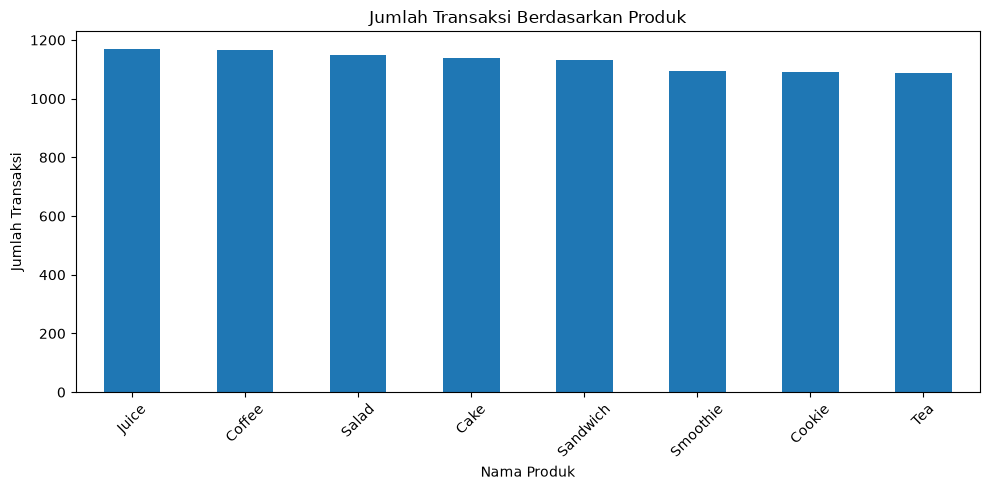

In [4]:
# Menghitung jumlah transaksi untuk setiap produk
jumlah_produk = df["Item"].value_counts()

display(jumlah_produk)

# Membuat diagram batang
jumlah_produk.plot(kind="bar", figsize=(10, 5))

plt.title("Jumlah Transaksi Berdasarkan Produk")
plt.xlabel("Nama Produk")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insight

Berdasarkan analisis, Juice menjadi produk dengan jumlah transaksi tertinggi, yaitu 1.171 transaksi, sedangkan Tea memiliki jumlah terendah, yaitu 1.089 transaksi. Selisih keduanya sebesar 82 transaksi. Hal ini menunjukkan bahwa frekuensi transaksi untuk setiap produk relatif merata dan tidak terdapat perbedaan yang terlalu besar.

Temuan ini dapat digunakan sebagai gambaran awal untuk mengevaluasi penjualan produk. Namun, penentuan produk dengan kontribusi pendapatan tertinggi memerlukan analisis tambahan berdasarkan total penjualan.

## 3. Analisis Metode Pembayaran

Analisis ini bertujuan mengetahui metode pembayaran yang paling sering digunakan dalam transaksi. Data dengan nilai `Payment Method` kosong tidak disertakan dalam perhitungan.

Payment Method
Digital Wallet    2291
Credit Card       2273
Cash              2258
Name: count, dtype: int64

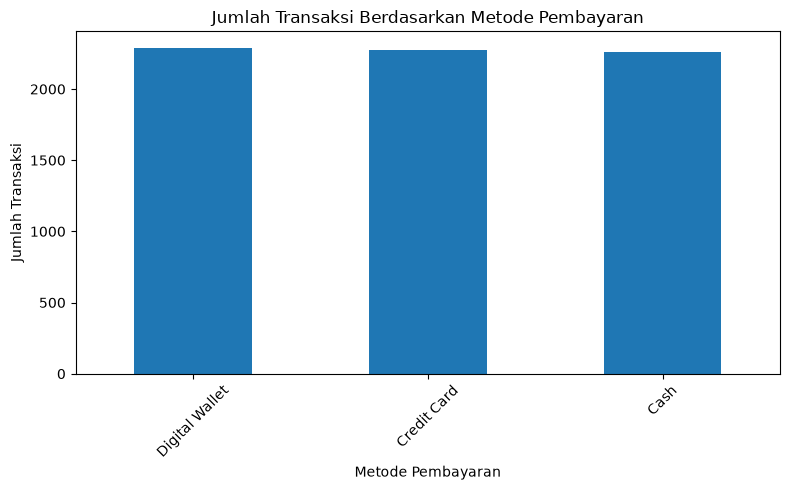

In [5]:
# Menghitung frekuensi setiap metode pembayaran
jumlah_pembayaran = df["Payment Method"].value_counts()

display(jumlah_pembayaran)

# Membuat diagram batang
jumlah_pembayaran.plot(kind="bar", figsize=(8, 5))

plt.title("Jumlah Transaksi Berdasarkan Metode Pembayaran")
plt.xlabel("Metode Pembayaran")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insight

Digital Wallet merupakan metode pembayaran yang paling sering tercatat, yaitu sebanyak 2.291 transaksi. Credit Card mencatat 2.273 transaksi, sedangkan Cash mencatat 2.258 transaksi. Selisih antara jumlah tertinggi dan terendah hanya 33 transaksi, sehingga penggunaan ketiga metode pembayaran relatif merata pada data yang tersedia.

Namun, terdapat 3.178 nilai kosong pada kolom `Payment Method`. Oleh karena itu, hasil analisis belum mewakili seluruh 10.000 transaksi dan perlu ditafsirkan dengan mempertimbangkan keterbatasan data tersebut.

## 4. Analisis Lokasi Transaksi

Analisis ini bertujuan mengetahui distribusi transaksi berdasarkan lokasi pelayanan, yaitu `In-store` dan `Takeaway`. Nilai kosong pada kolom `Location` tidak disertakan dalam perhitungan.

Location
Takeaway    3022
In-store    3017
Name: count, dtype: int64

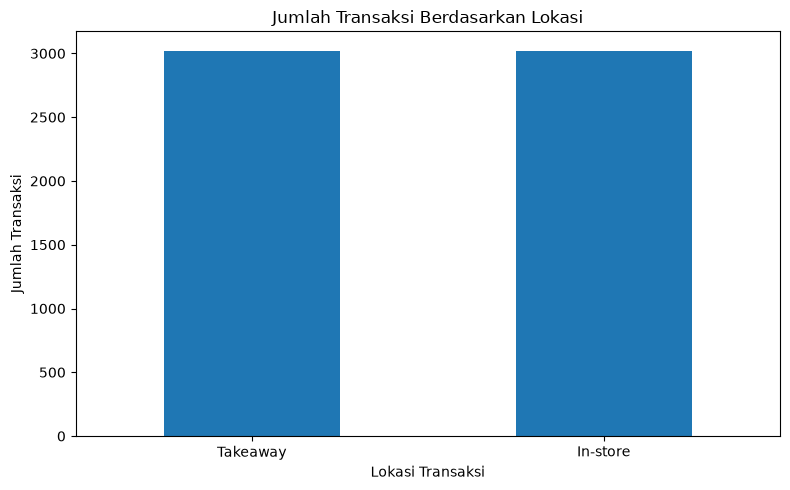

In [6]:
# Menghitung jumlah transaksi berdasarkan lokasi
jumlah_lokasi = df["Location"].value_counts()

display(jumlah_lokasi)

# Membuat diagram batang
jumlah_lokasi.plot(kind="bar", figsize=(8, 5))

plt.title("Jumlah Transaksi Berdasarkan Lokasi")
plt.xlabel("Lokasi Transaksi")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Insight

Takeaway mencatat 3.022 transaksi, sedangkan In-store mencatat 3.017 transaksi. Selisih hanya 5 transaksi menunjukkan bahwa jumlah transaksi pada kedua lokasi hampir seimbang. Belum dapat disimpulkan bahwa salah satu lokasi lebih menguntungkan karena analisis ini hanya menghitung frekuensi transaksi, bukan pendapatan.

Selain itu, terdapat 3.961 nilai kosong pada kolom `Location`, sehingga hasil perlu ditafsirkan dengan mempertimbangkan keterbatasan data.

## 5. Analisis Tren Transaksi Bulanan

Analisis ini bertujuan mengetahui perubahan jumlah transaksi dari bulan ke bulan selama tahun 2023. Transaksi dengan tanggal kosong atau tidak valid tidak disertakan dalam perhitungan.

Transaction Date
2023-01    818
2023-02    727
2023-03    827
2023-04    774
2023-05    777
2023-06    818
2023-07    791
2023-08    803
2023-09    788
2023-10    838
2023-11    784
2023-12    795
dtype: int64

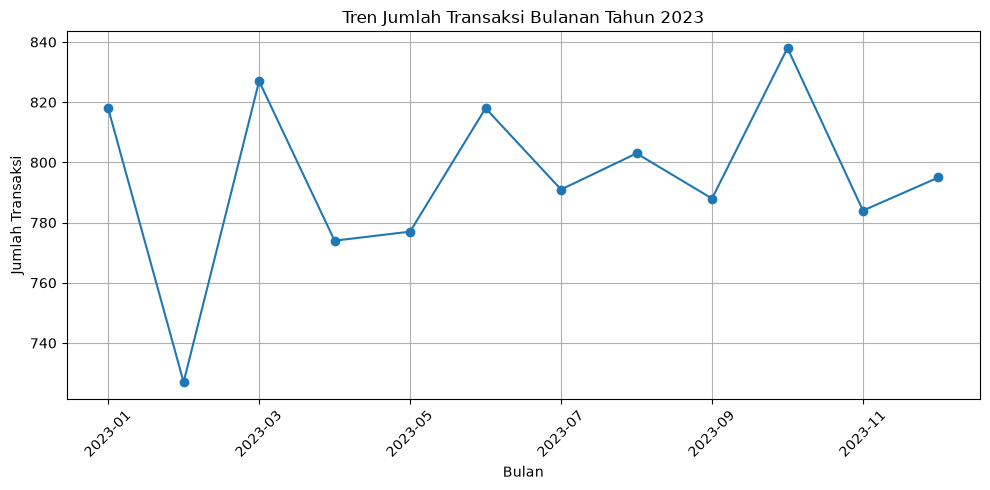

In [7]:
# Mengubah kolom tanggal menjadi format datetime
df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

# Menghitung jumlah transaksi setiap bulan
transaksi_bulanan = (
    df.dropna(subset=["Transaction Date"])
    .groupby(df["Transaction Date"].dt.to_period("M"))
    .size()
)

# Mengubah indeks periode menjadi teks
transaksi_bulanan.index = transaksi_bulanan.index.astype(str)

display(transaksi_bulanan)

# Membuat diagram garis
transaksi_bulanan.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Tren Jumlah Transaksi Bulanan Tahun 2023")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Insight

Berdasarkan analisis bulanan, Oktober 2023 memiliki jumlah transaksi tertinggi sebanyak 838 transaksi, sedangkan Februari 2023 memiliki jumlah transaksi terendah sebanyak 727 transaksi. Selisih keduanya adalah 111 transaksi.

Jumlah transaksi mengalami fluktuasi selama tahun 2023 dan tidak menunjukkan peningkatan yang konsisten setiap bulan. Analisis lanjutan diperlukan untuk mengetahui faktor yang mungkin berkaitan dengan perubahan aktivitas transaksi tersebut.

## 6. Analisis Total Penjualan Berdasarkan Produk

Analisis ini bertujuan membandingkan total nilai penjualan setiap produk. Perhitungan menggunakan kolom `Total Spent` dan mengabaikan nilai kosong pada kolom `Item` maupun `Total Spent`.

Item
Salad       17320.0
Sandwich    13664.0
Smoothie    13320.0
Juice       10509.0
Cake        10395.0
Coffee       7062.0
Tea          4951.5
Cookie       3223.0
Name: Total Spent, dtype: float64

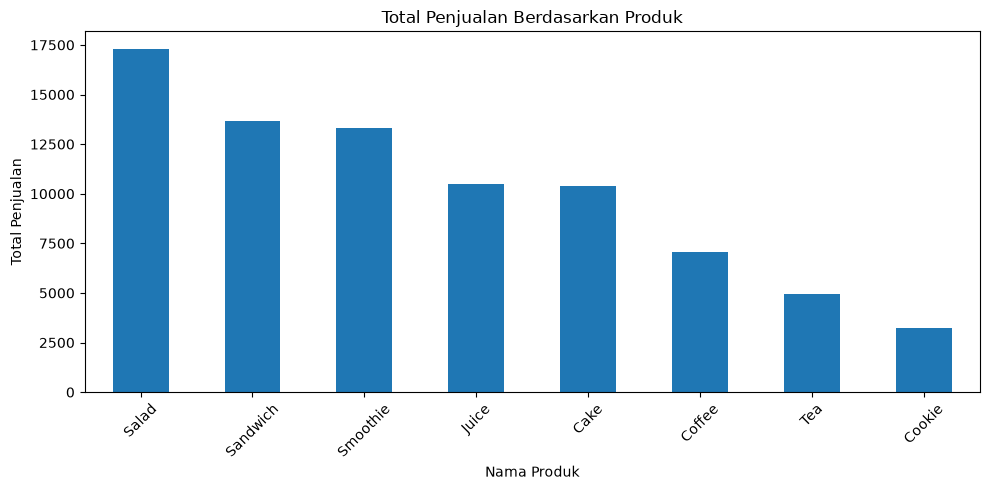

In [8]:
# Menghitung total penjualan berdasarkan produk
penjualan_produk = (
    df.dropna(subset=["Item", "Total Spent"])
    .groupby("Item")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

display(penjualan_produk)

# Membuat diagram batang
penjualan_produk.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Total Penjualan Berdasarkan Produk")
plt.xlabel("Nama Produk")
plt.ylabel("Total Penjualan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insight

Salad menghasilkan total penjualan tertinggi sebesar 17.320,0, diikuti oleh Sandwich sebesar 13.664,0 dan Smoothie sebesar 13.320,0. Sementara itu, Cookie memiliki total penjualan terendah sebesar 3.223,0.

Hasil ini berbeda dari analisis frekuensi transaksi sebelumnya, ketika Juice menjadi produk yang paling sering muncul. Hal tersebut menunjukkan bahwa produk dengan frekuensi transaksi tertinggi belum tentu menghasilkan total penjualan terbesar. Salad dapat menjadi salah satu produk yang perlu diperhatikan dalam evaluasi penjualan, sedangkan faktor rendahnya total penjualan Cookie masih perlu diteliti lebih lanjut.

## 7. Kesimpulan Exploratory Data Analysis

Tahap EDA dilakukan untuk memahami pola transaksi pada dataset Dirty Cafe Sales. Analisis mencakup frekuensi transaksi berdasarkan produk, metode pembayaran, lokasi transaksi, tren bulanan, serta total penjualan berdasarkan produk.

Hasil analisis menunjukkan bahwa Juice memiliki frekuensi transaksi tertinggi, Digital Wallet merupakan metode pembayaran yang paling sering tercatat, dan Takeaway memiliki jumlah transaksi sedikit lebih tinggi dibandingkan In-store. Pada analisis bulanan, Oktober 2023 mencatat transaksi terbanyak, sedangkan Februari 2023 mencatat transaksi paling sedikit. Berdasarkan total penjualan, Salad menempati peringkat pertama.

Hasil ini memberikan gambaran awal mengenai aktivitas penjualan kafe. Namun, sejumlah nilai masih kosong sehingga setiap temuan perlu ditafsirkan sesuai jumlah data yang tersedia pada masing-masing analisis.